# 模块一：描述性统计分析
## 电商智能客服 RAG 系统多维度评测与根因分析

**分析目的**：建立系统质量全景图，回答"整体水平怎么样"

**分析内容**：
1. 总体通过率与各维度得分分布
2. 6 个分支通过率对比
3. 5 种测试类型通过率对比
4. 3 个难度等级通过率分布
5. 7 个评分维度均值与标准差
6. 幻觉率与违规率分布

**产出图表**：分支通过率柱状图、维度评分雷达图、难度×类型热力图、评分分布箱线图

## 1.1 环境配置与数据加载

In [1]:
import os

# 路径自适应：无论从哪里启动 Jupyter，都切到项目根目录
NOTEBOOK_DIR = os.getcwd()
if os.path.basename(NOTEBOOK_DIR) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()

print("✅ 项目根目录:", PROJECT_ROOT)
print("eval_output 存在:", os.path.exists('eval_output'))
print("目标文件存在:", os.path.exists('eval_results_20260807_142126.json'.join(['eval_output/', ''])) if False else os.path.exists('eval_output/eval_results_20260807_142126.json'))

✅ 项目根目录: C:\Users\Darren\Desktop\ecommerce_rag_eval
eval_output 存在: True
目标文件存在: True


In [2]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
from collections import Counter

# ========== 中文字体配置（Windows）==========
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 200
matplotlib.rcParams['savefig.bbox'] = 'tight'

# ========== 配色方案 ==========
BRANCH_COLORS = {
    '商品咨询': '#4ECDC4',
    '订单查询': '#45B7D1',
    '退款换货': '#FFA07A',
    '投诉': '#FF6B6B',
    '其他': '#95E1D3',
    '边界混淆': '#C44569'
}
TYPE_COLORS = {
    'single_turn': '#4ECDC4',
    'multi_turn': '#45B7D1',
    'boundary': '#FFA07A',
    'prohibited': '#FF6B6B',
    'adversarial': '#C44569'
}
DIFFICULTY_COLORS = {'简单': '#51CF66', '中等': '#FFD43B', '困难': '#FF6B6B'}

# ========== 创建输出目录 ==========
os.makedirs('charts', exist_ok=True)
os.makedirs('analysis_output', exist_ok=True)

print('✅ 环境配置完成')

✅ 环境配置完成


In [3]:
# ========== 加载评测结果 ==========
# 修改为你的实际文件路径
RESULTS_PATH = 'eval_output/eval_results_20260807_142126.json'

with open(RESULTS_PATH, 'r', encoding='utf-8') as f:
    raw_results = json.load(f)

print(f'加载结果文件: {RESULTS_PATH}')
print(f'总记录数: {len(raw_results)}')
print(f'\n单条数据结构示例:')
sample = raw_results[0]
for k, v in sample.items():
    if k == 'score':
        print(f'  {k}: {{...}}')
    elif k == 'actual_response':
        print(f'  {k}: {str(v)[:80]}...')
    else:
        print(f'  {k}: {v}')
print(f'\nscore 字段:')
for k, v in sample.get('score', {}).items():
    print(f'  {k}: {v}')

加载结果文件: eval_output/eval_results_20260807_142126.json
总记录数: 505

单条数据结构示例:
  case_id: TC-INTENT-001
  test_type: single_turn
  category: 商品咨询
  difficulty: 简单
  user_query: 索尼WF-1000XM5蓝牙耳机的降噪效果怎么样？
  expected_intent: consult
  expected_branch: 商品咨询
  expected_if_else_path: #3:IF
  expected_answer_contains: 降噪,42dB
  must_not: 
  expected_complaint_level: None
  expected_human_handoff: False
  expected_retrieval_hit: True
  boundary_value: None
  is_multi_turn: False
  conversation_id: a608071e-16f8-49d3-b432-1261a81bbea2
  actual_response: **索尼WF-1000XM5蓝牙耳机**的降噪深度可达42dB，能有效隔绝外界噪音，适合通勤族和学生党使用。关于**续航时间**，这款耳机可以提供30小时的播放...
  score: {...}

score 字段:
  intent_accuracy: 5
  branch_routing: 5
  answer_relevance: 5
  information_completeness: 5
  faithfulness: 5
  tone_compliance: 5
  must_not_violation: False
  boundary_correctness: 5
  is_hallucination: False
  contains_expected_points: True
  handoff_correctness: -1
  comment: [预检修正]must_not未违规(精确匹配)。准确回应商品咨询意图，覆盖降噪与42dB要点，无违规表述，信息真实完整。


In [4]:
# ========== 展平为 DataFrame ==========
rows = []
for r in raw_results:
    s = r.get('score', {})
    # 处理列表字段（JSON 中可能是字符串或列表）
    def fmt_list(v):
        if isinstance(v, list):
            return ','.join(v)
        return str(v) if v else ''

    row = {
        'case_id': r.get('case_id', ''),
        'test_type': r.get('test_type', ''),
        'category': r.get('category', ''),
        'difficulty': r.get('difficulty', ''),
        'is_multi_turn': r.get('is_multi_turn', False),
        # ===== 补充的评测集原始字段（供模块二归因使用）=====
        'user_query': r.get('user_query', ''),
        'expected_intent': r.get('expected_intent', ''),
        'expected_branch': r.get('expected_branch', ''),
        'expected_if_else_path': fmt_list(r.get('expected_if_else_path', '')),
        'expected_answer_contains': fmt_list(r.get('expected_answer_contains', '')),
        'must_not': fmt_list(r.get('must_not', '')),
        'expected_complaint_level': r.get('expected_complaint_level'),
        'expected_human_handoff': r.get('expected_human_handoff', False),
        'expected_retrieval_hit': r.get('expected_retrieval_hit'),
        'conversation_id': r.get('conversation_id', ''),
        'boundary_value': r.get('boundary_value'),
        # ===== 评分字段 =====
        'intent_accuracy': s.get('intent_accuracy', 0),
        'branch_routing': s.get('branch_routing', 0),
        'answer_relevance': s.get('answer_relevance', 0),
        'information_completeness': s.get('information_completeness', 0),
        'faithfulness': s.get('faithfulness', 0),
        'tone_compliance': s.get('tone_compliance', 0),
        'boundary_correctness': s.get('boundary_correctness', 0),
        'must_not_violation': s.get('must_not_violation', False),
        'is_hallucination': s.get('is_hallucination', False),
        'contains_expected_points': s.get('contains_expected_points', False),
        'handoff_correctness': s.get('handoff_correctness', -1),
        'comment': s.get('comment', ''),
        'actual_response': r.get('actual_response', ''),
    }
    rows.append(row)

df = pd.DataFrame(rows)

# ========== 定义通过判定（宽松 + 严格两种口径）==========
df['is_passed'] = (df['branch_routing'] >= 4) & \
                  (~df['is_hallucination']) & \
                  (~df['must_not_violation'])
df['route_passed'] = df['branch_routing'] >= 4
df['route_passed_strict'] = df['branch_routing'] == 5
df['intent_passed'] = df['intent_accuracy'] >= 4
df['points_passed'] = df['contains_expected_points'] == True

print('✅ DataFrame 构建完成')
print(f'   形状: {df.shape}')
print(f'   列数: {len(df.columns)}')
print(f'   列名: {list(df.columns)}')
print('')
print('   通过判定分布:')
print(f'   分支路由通过(宽松>=4): {df["route_passed"].sum()}/{len(df)} = {df["route_passed"].mean()*100:.1f}%')
print(f'   分支路由通过(严格==5): {df["route_passed_strict"].sum()}/{len(df)} = {df["route_passed_strict"].mean()*100:.1f}%')
print(f'   综合通过: {df["is_passed"].sum()}/{len(df)} = {df["is_passed"].mean()*100:.1f}%')

✅ DataFrame 构建完成
   形状: (505, 34)
   列数: 34
   列名: ['case_id', 'test_type', 'category', 'difficulty', 'is_multi_turn', 'user_query', 'expected_intent', 'expected_branch', 'expected_if_else_path', 'expected_answer_contains', 'must_not', 'expected_complaint_level', 'expected_human_handoff', 'expected_retrieval_hit', 'conversation_id', 'boundary_value', 'intent_accuracy', 'branch_routing', 'answer_relevance', 'information_completeness', 'faithfulness', 'tone_compliance', 'boundary_correctness', 'must_not_violation', 'is_hallucination', 'contains_expected_points', 'handoff_correctness', 'comment', 'actual_response', 'is_passed', 'route_passed', 'route_passed_strict', 'intent_passed', 'points_passed']

   通过判定分布:
   分支路由通过(宽松>=4): 462/505 = 91.5%
   分支路由通过(严格==5): 461/505 = 91.3%
   综合通过: 455/505 = 90.1%


## 1.2 数据概览

In [5]:
# ========== 数据概览：分布统计 ==========
print('=' * 60)
print('📊 数据概览')
print('=' * 60)
print(f'\n总用例数: {len(df)}')

print(f'\n--- 按分支分布 ---')
cat_dist = df['category'].value_counts()
for cat, cnt in cat_dist.items():
    pct = cnt / len(df) * 100
    bar = '█' * int(pct / 2)
    print(f'  {cat:8s}: {cnt:3d} ({pct:5.1f}%) {bar}')

print(f'\n--- 按测试类型分布 ---')
type_dist = df['test_type'].value_counts()
for tt, cnt in type_dist.items():
    pct = cnt / len(df) * 100
    bar = '█' * int(pct / 2)
    print(f'  {tt:15s}: {cnt:3d} ({pct:5.1f}%) {bar}')

print(f'\n--- 按难度分布 ---')
for d in ['简单', '中等', '困难']:
    cnt = (df['difficulty'] == d).sum()
    pct = cnt / len(df) * 100
    bar = '█' * int(pct / 2)
    print(f'  {d}: {cnt:3d} ({pct:5.1f}%) {bar}')

print(f'\n--- 多轮对话 ---')
mt_cnt = df['is_multi_turn'].sum()
print(f'  多轮用例: {mt_cnt} ({mt_cnt/len(df)*100:.1f}%)')
print(f'  单轮用例: {len(df)-mt_cnt} ({(len(df)-mt_cnt)/len(df)*100:.1f}%)')

📊 数据概览

总用例数: 505

--- 按分支分布 ---
  商品咨询    : 281 ( 55.6%) ███████████████████████████
  退款换货    :  70 ( 13.9%) ██████
  其他      :  49 (  9.7%) ████
  投诉      :  47 (  9.3%) ████
  订单查询    :  36 (  7.1%) ███
  边界混淆    :  22 (  4.4%) ██

--- 按测试类型分布 ---
  single_turn    : 382 ( 75.6%) █████████████████████████████████████
  adversarial    :  48 (  9.5%) ████
  boundary       :  35 (  6.9%) ███
  prohibited     :  23 (  4.6%) ██
  multi_turn     :  17 (  3.4%) █

--- 按难度分布 ---
  简单: 190 ( 37.6%) ██████████████████
  中等: 182 ( 36.0%) ██████████████████
  困难: 133 ( 26.3%) █████████████

--- 多轮对话 ---
  多轮用例: 17 (3.4%)
  单轮用例: 488 (96.6%)


## 1.3 总体准确率与问题检测

In [6]:
# ========== 总体指标 ==========
total = len(df)

intent_ok = df['intent_passed'].sum()
route_ok = df['route_passed'].sum()
pts_ok = df['points_passed'].sum()
hal_cnt = df['is_hallucination'].sum()
vio_cnt = df['must_not_violation'].sum()

print('=' * 60)
print('📊 总体准确率')
print('=' * 60)
print(f'\n--- 准确率 ---')
print(f'  意图识别: {intent_ok}/{total} = {intent_ok/total*100:.1f}%')
print(f'  分支路由: {route_ok}/{total} = {route_ok/total*100:.1f}%')
print(f'  要点覆盖: {pts_ok}/{total} = {pts_ok/total*100:.1f}%')
print(f'  综合通过: {df["is_passed"].sum()}/{total} = {df["is_passed"].mean()*100:.1f}%')

print(f'\n--- 问题检测 ---')
print(f'  🚨 幻觉率: {hal_cnt}/{total} = {hal_cnt/total*100:.1f}%')
print(f'  ⚠️ 禁止表述违规率: {vio_cnt}/{total} = {vio_cnt/total*100:.1f}%')

print(f'\n--- 关键指标解读 ---')
print(f'  意图识别准确率 {intent_ok/total*100:.1f}% 意味着 {total-intent_ok} 条用例的意图被误判')
print(f'  分支路由准确率 {route_ok/total*100:.1f}% 意味着 {total-route_ok} 条用例路由到了错误分支')
print(f'  幻觉率 {hal_cnt/total*100:.1f}% 意味着 {hal_cnt} 条回复包含虚构信息')
print(f'  违规率 {vio_cnt/total*100:.1f}% 意味着 {vio_cnt} 条回复包含禁止表述')

📊 总体准确率

--- 准确率 ---
  意图识别: 473/505 = 93.7%
  分支路由: 462/505 = 91.5%
  要点覆盖: 440/505 = 87.1%
  综合通过: 455/505 = 90.1%

--- 问题检测 ---
  🚨 幻觉率: 13/505 = 2.6%
  ⚠️ 禁止表述违规率: 4/505 = 0.8%

--- 关键指标解读 ---
  意图识别准确率 93.7% 意味着 32 条用例的意图被误判
  分支路由准确率 91.5% 意味着 43 条用例路由到了错误分支
  幻觉率 2.6% 意味着 13 条回复包含虚构信息
  违规率 0.8% 意味着 4 条回复包含禁止表述


## 1.4 各分支通过率分析

In [7]:
# ========== 6 分支通过率 ==========
print('=' * 60)
print('📊 各分支通过率')
print('=' * 60)

branch_stats = []
for cat in ['商品咨询', '订单查询', '退款换货', '投诉', '其他', '边界混淆']:
    cdf = df[df['category'] == cat]
    if len(cdf) == 0:
        continue
    passed = cdf['route_passed'].sum()
    failed = len(cdf) - passed
    pass_rate = passed / len(cdf)
    avg_route = cdf['branch_routing'].mean()
    avg_overall = cdf[['intent_accuracy', 'branch_routing', 'answer_relevance',
                       'information_completeness', 'faithfulness', 'tone_compliance',
                       'boundary_correctness']].mean().mean()
    hal = cdf['is_hallucination'].sum()
    vio = cdf['must_not_violation'].sum()
    branch_stats.append({
        'branch': cat, 'total': len(cdf), 'passed': passed, 'failed': failed,
        'pass_rate': pass_rate, 'avg_route': avg_route, 'avg_overall': avg_overall,
        'hallucination': hal, 'violation': vio
    })
    status = '✅' if pass_rate >= 0.9 else ('⚠️' if pass_rate >= 0.8 else '🚨')
    print(f'  {status} {cat:8s}: {passed:3d}/{len(cdf):3d} = {pass_rate*100:5.1f}% | '
          f'均分{avg_route:.2f} | 幻觉{hal} 违规{vio}')

branch_df = pd.DataFrame(branch_stats)
print(f'\n{branch_df.to_string(index=False)}')

📊 各分支通过率
  ✅ 商品咨询    : 268/281 =  95.4% | 均分4.83 | 幻觉4 违规0
  ✅ 订单查询    :  36/ 36 = 100.0% | 均分5.00 | 幻觉0 违规0
  ⚠️ 退款换货    :  61/ 70 =  87.1% | 均分4.56 | 幻觉2 违规4
  🚨 投诉      :  37/ 47 =  78.7% | 均分4.23 | 幻觉3 违规0
  ✅ 其他      :  46/ 49 =  93.9% | 均分4.69 | 幻觉2 违规0
  🚨 边界混淆    :  14/ 22 =  63.6% | 均分3.95 | 幻觉2 违规0

branch  total  passed  failed  pass_rate  avg_route  avg_overall  hallucination  violation
  商品咨询    281     268      13   0.953737   4.832740     4.796136              4          0
  订单查询     36      36       0   1.000000   5.000000     4.845238              0          0
  退款换货     70      61       9   0.871429   4.557143     4.714286              2          4
    投诉     47      37      10   0.787234   4.234043     4.474164              3          0
    其他     49      46       3   0.938776   4.693878     4.723032              2          0
  边界混淆     22      14       8   0.636364   3.954545     4.415584              2          0


## 1.5 各测试类型通过率分析

In [8]:
# ========== 5 种测试类型通过率 ==========
print('=' * 60)
print('📊 各测试类型通过率')
print('=' * 60)

type_stats = []
for tt in ['single_turn', 'multi_turn', 'boundary', 'prohibited', 'adversarial']:
    tdf = df[df['test_type'] == tt]
    if len(tdf) == 0:
        continue
    passed = tdf['route_passed'].sum()
    failed = len(tdf) - passed
    pass_rate = passed / len(tdf)
    avg_route = tdf['branch_routing'].mean()
    hal = tdf['is_hallucination'].sum()
    vio = tdf['must_not_violation'].sum()
    type_stats.append({
        'test_type': tt, 'total': len(tdf), 'passed': passed, 'failed': failed,
        'pass_rate': pass_rate, 'avg_route': avg_route,
        'hallucination': hal, 'violation': vio
    })
    status = '✅' if pass_rate >= 0.9 else ('⚠️' if pass_rate >= 0.8 else '🚨')
    print(f'  {status} {tt:15s}: {passed:3d}/{len(tdf):3d} = {pass_rate*100:5.1f}% | '
          f'均分{avg_route:.2f} | 幻觉{hal} 违规{vio}')

type_df = pd.DataFrame(type_stats)
print(f'\n{type_df.to_string(index=False)}')

📊 各测试类型通过率
  ✅ single_turn    : 362/382 =  94.8% | 均分4.82 | 幻觉5 违规0
  ⚠️ multi_turn     :  14/ 17 =  82.4% | 均分4.29 | 幻觉2 违规0
  ⚠️ boundary       :  31/ 35 =  88.6% | 均分4.54 | 幻觉0 违规4
  🚨 prohibited     :  17/ 23 =  73.9% | 均分4.00 | 幻觉2 违规0
  🚨 adversarial    :  38/ 48 =  79.2% | 均分4.31 | 幻觉4 违规0

  test_type  total  passed  failed  pass_rate  avg_route  hallucination  violation
single_turn    382     362      20   0.947644   4.821990              5          0
 multi_turn     17      14       3   0.823529   4.294118              2          0
   boundary     35      31       4   0.885714   4.542857              0          4
 prohibited     23      17       6   0.739130   4.000000              2          0
adversarial     48      38      10   0.791667   4.312500              4          0


## 1.6 各难度通过率分析

In [9]:
# ========== 3 个难度等级通过率 ==========
print('=' * 60)
print('📊 各难度通过率')
print('=' * 60)

diff_stats = []
for d in ['简单', '中等', '困难']:
    ddf = df[df['difficulty'] == d]
    if len(ddf) == 0:
        continue
    passed = ddf['route_passed'].sum()
    failed = len(ddf) - passed
    pass_rate = passed / len(ddf)
    avg_route = ddf['branch_routing'].mean()
    hal = ddf['is_hallucination'].sum()
    diff_stats.append({
        'difficulty': d, 'total': len(ddf), 'passed': passed, 'failed': failed,
        'pass_rate': pass_rate, 'avg_route': avg_route, 'hallucination': hal
    })
    status = '✅' if pass_rate >= 0.9 else ('⚠️' if pass_rate >= 0.8 else '🚨')
    print(f'  {status} {d}: {passed:3d}/{len(ddf):3d} = {pass_rate*100:5.1f}% | '
          f'均分{avg_route:.2f} | 幻觉{hal}')

diff_df = pd.DataFrame(diff_stats)
print(f'\n{diff_df.to_string(index=False)}')

# 反直觉发现检测
print(f'\n--- 反直觉发现 ---')
if len(diff_stats) >= 2:
    if diff_stats[1]['pass_rate'] < diff_stats[2]['pass_rate']:
        print(f'  ⚠️ 中等难度通过率({diff_stats[1]["pass_rate"]*100:.1f}%) 低于 困难难度({diff_stats[2]["pass_rate"]*100:.1f}%)')
        print(f'     可能原因：中等难度用例集中在退款换货/投诉等复杂分支，而困难用例含更多商品咨询（通过率高）')

📊 各难度通过率
  ✅ 简单: 184/190 =  96.8% | 均分4.91 | 幻觉0
  ⚠️ 中等: 158/182 =  86.8% | 均分4.50 | 幻觉9
  ✅ 困难: 120/133 =  90.2% | 均分4.67 | 幻觉4

difficulty  total  passed  failed  pass_rate  avg_route  hallucination
        简单    190     184       6   0.968421   4.910526              0
        中等    182     158      24   0.868132   4.500000              9
        困难    133     120      13   0.902256   4.669173              4

--- 反直觉发现 ---
  ⚠️ 中等难度通过率(86.8%) 低于 困难难度(90.2%)
     可能原因：中等难度用例集中在退款换货/投诉等复杂分支，而困难用例含更多商品咨询（通过率高）


## 1.7 评分维度统计分析

In [10]:
# ========== 7 个数值评分维度的描述性统计 ==========
score_cols = ['intent_accuracy', 'branch_routing', 'answer_relevance',
              'information_completeness', 'faithfulness', 'tone_compliance',
              'boundary_correctness']

score_names_cn = {
    'intent_accuracy': '意图识别',
    'branch_routing': '分支路由',
    'answer_relevance': '答案相关性',
    'information_completeness': '信息完整性',
    'faithfulness': '忠实度',
    'tone_compliance': '语气合规',
    'boundary_correctness': '边界正确性'
}

print('=' * 60)
print('📊 评分维度描述性统计（0-5 分）')
print('=' * 60)
print(f'\n{"维度":12s} {"均值":>6s} {"标准差":>6s} {"最小值":>6s} {"中位数":>6s} {"最大值":>6s} {">=4占比":>7s}')
print('-' * 60)

dim_stats = []
for col in score_cols:
    mean_val = df[col].mean()
    std_val = df[col].std()
    min_val = df[col].min()
    median_val = df[col].median()
    max_val = df[col].max()
    pass_pct = (df[col] >= 4).mean() * 100
    name = score_names_cn[col]
    print(f'{name:12s} {mean_val:6.2f} {std_val:6.2f} {min_val:6.1f} {median_val:6.1f} {max_val:6.1f} {pass_pct:6.1f}%')
    dim_stats.append({
        'dimension': name, 'mean': mean_val, 'std': std_val,
        'min': min_val, 'median': median_val, 'max': max_val,
        'pass_rate': pass_pct / 100
    })

print(f'\n--- 解读 ---')
weakest = min(dim_stats, key=lambda x: x['mean'])
strongest = max(dim_stats, key=lambda x: x['mean'])
highest_var = max(dim_stats, key=lambda x: x['std'])
print(f'  最强维度: {strongest["dimension"]}（均值 {strongest["mean"]:.2f}）')
print(f'  最弱维度: {weakest["dimension"]}（均值 {weakest["mean"]:.2f}）')
print(f'  波动最大: {highest_var["dimension"]}（标准差 {highest_var["std"]:.2f}）→ 该维度在不同用例间表现不稳定')

📊 评分维度描述性统计（0-5 分）

维度               均值    标准差    最小值    中位数    最大值   >=4占比
------------------------------------------------------------
意图识别           4.81   0.77    0.0    5.0    5.0   93.7%
分支路由           4.70   1.03    0.0    5.0    5.0   91.5%
答案相关性          4.70   0.94    0.0    5.0    5.0   91.9%
信息完整性          4.32   1.28    0.0    5.0    5.0   86.1%
忠实度            4.85   0.64    0.0    5.0    5.0   95.8%
语气合规           4.93   0.38    0.0    5.0    5.0   99.4%
边界正确性          4.82   0.67    0.0    5.0    5.0   98.2%

--- 解读 ---
  最强维度: 语气合规（均值 4.93）
  最弱维度: 信息完整性（均值 4.32）
  波动最大: 信息完整性（标准差 1.28）→ 该维度在不同用例间表现不稳定


## 1.8 可视化：分支通过率柱状图

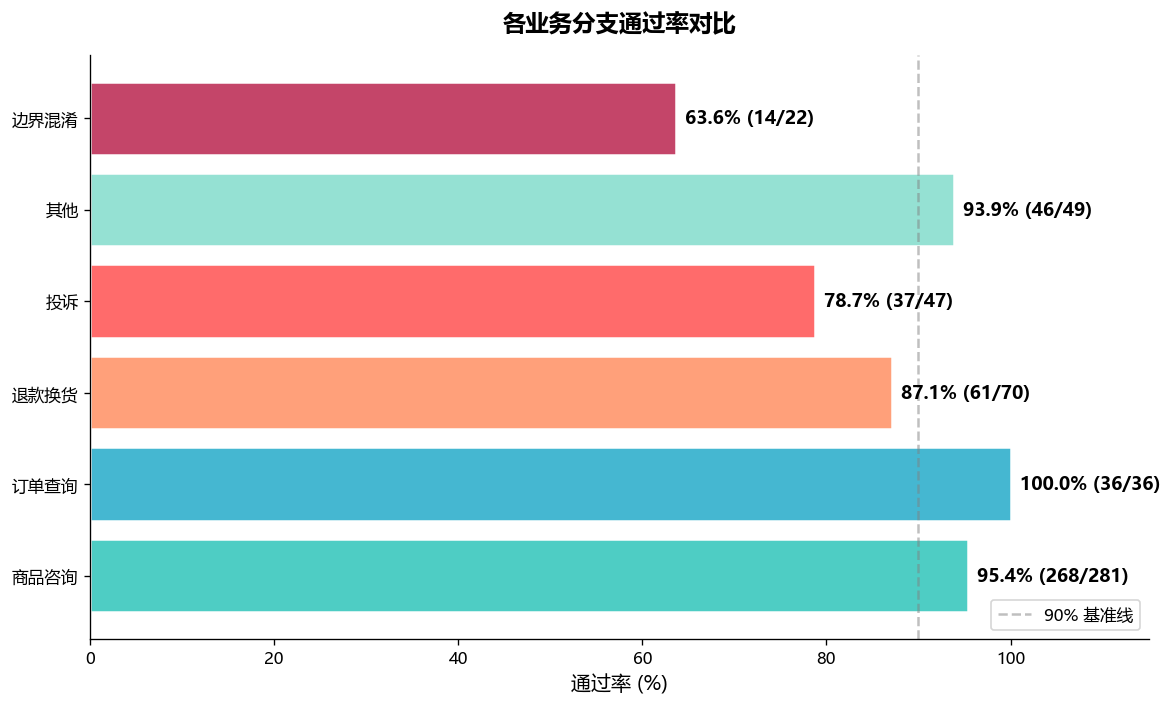

💾 已保存: charts/01_branch_pass_rate.png


In [11]:
# ========== 图1：6 分支通过率柱状图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

branches = branch_df['branch'].tolist()
pass_rates = branch_df['pass_rate'].tolist()
colors = [BRANCH_COLORS.get(b, '#888888') for b in branches]

bars = ax.barh(branches, [r * 100 for r in pass_rates], color=colors, edgecolor='white', linewidth=1.5)

for bar, rate, case_total, case_failed in zip(bars, pass_rates, branch_df['total'], branch_df['failed']):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height() / 2,
            f'{width:.1f}% ({case_total-case_failed}/{case_total})',
            ha='left', va='center', fontsize=11, fontweight='bold')

ax.axvline(x=90, color='gray', linestyle='--', alpha=0.5, label='90% 基准线')

ax.set_xlabel('通过率 (%)', fontsize=12)
ax.set_title('各业务分支通过率对比', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 115)
ax.legend(loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('charts/01_branch_pass_rate.png')
plt.show()
print('💾 已保存: charts/01_branch_pass_rate.png')

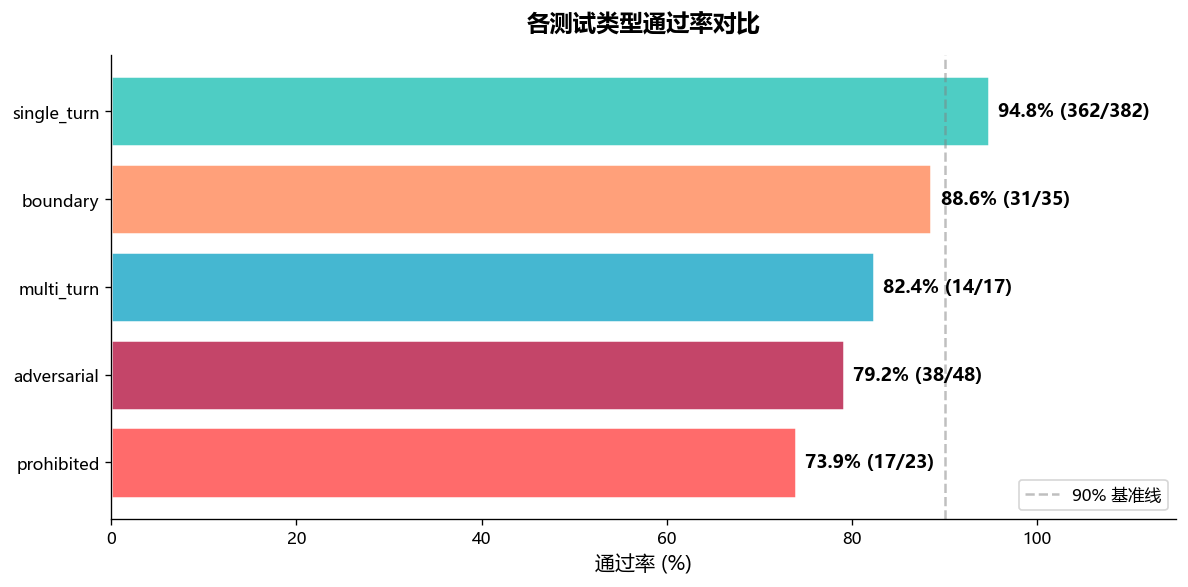

💾 已保存: charts/02_test_type_pass_rate.png


In [12]:
# ========== 图2：各测试类型通过率柱状图 ==========
fig, ax = plt.subplots(figsize=(10, 5))

types = type_df['test_type'].tolist()
type_pass_rates = type_df['pass_rate'].tolist()
type_colors_list = [TYPE_COLORS.get(t, '#888888') for t in types]

# 按通过率排序（从低到高，突出问题）
sorted_idx = sorted(range(len(type_pass_rates)), key=lambda i: type_pass_rates[i])
types_sorted = [types[i] for i in sorted_idx]
rates_sorted = [type_pass_rates[i] * 100 for i in sorted_idx]
colors_sorted = [type_colors_list[i] for i in sorted_idx]

bars = ax.barh(types_sorted, rates_sorted, color=colors_sorted, edgecolor='white', linewidth=1.5)

for bar, rate, case_total, case_failed in zip(bars, rates_sorted,
                                     [type_df.iloc[i]['total'] for i in sorted_idx],
                                     [type_df.iloc[i]['failed'] for i in sorted_idx]):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height() / 2,
            f'{width:.1f}% ({int(case_total-case_failed)}/{int(case_total)})',
            ha='left', va='center', fontsize=11, fontweight='bold')

ax.axvline(x=90, color='gray', linestyle='--', alpha=0.5, label='90% 基准线')
ax.set_xlabel('通过率 (%)', fontsize=12)
ax.set_title('各测试类型通过率对比', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 115)
ax.legend(loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('charts/02_test_type_pass_rate.png')
plt.show()
print('💾 已保存: charts/02_test_type_pass_rate.png')

## 1.9 可视化：评分维度雷达图

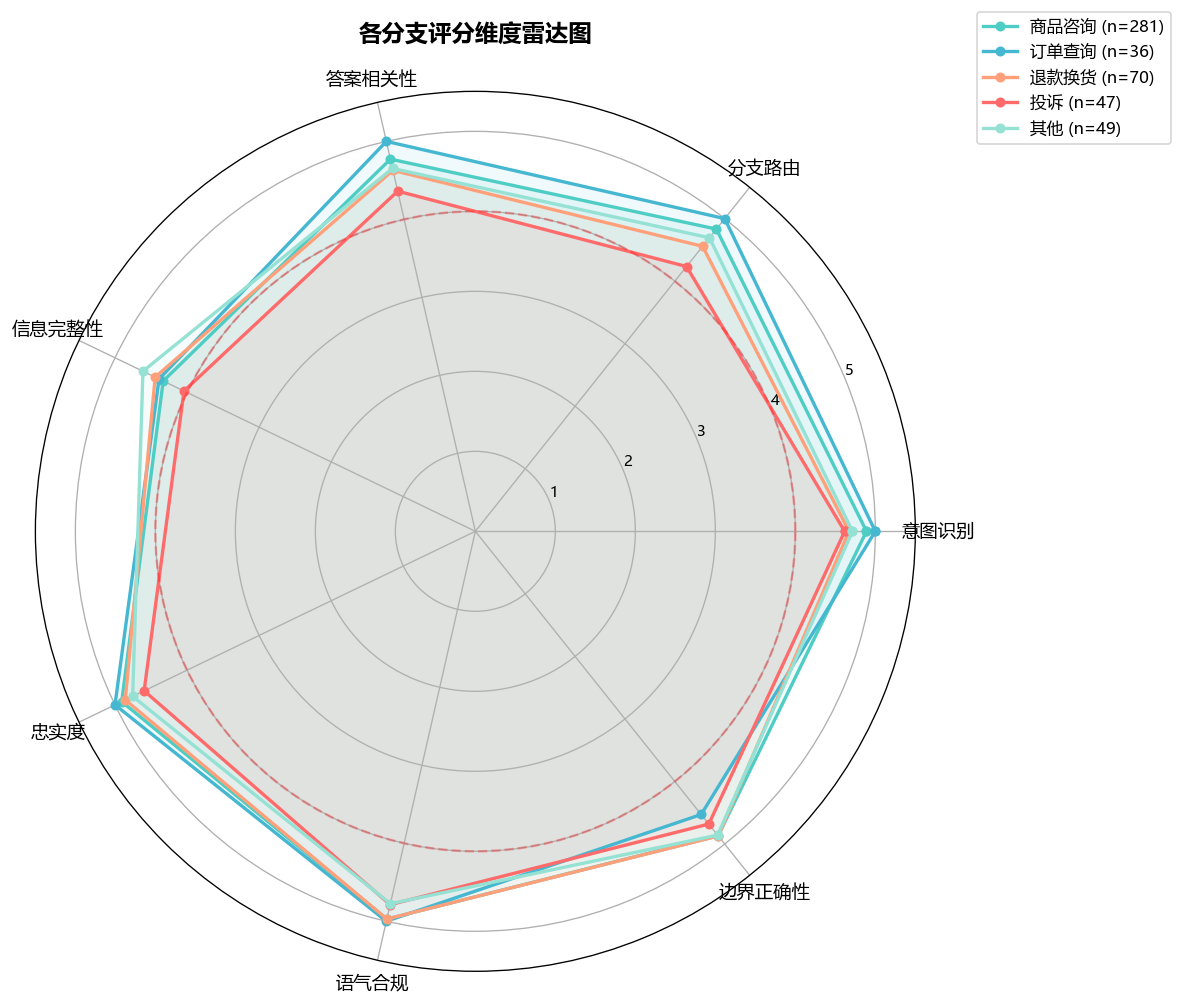

💾 已保存: charts/03_dimension_radar.png


In [13]:
# ========== 图3：7 维度评分雷达图 ==========
categories_radar = [score_names_cn[c] for c in score_cols]
N = len(categories_radar)

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for cat in ['商品咨询', '订单查询', '退款换货', '投诉', '其他']:
    cdf = df[df['category'] == cat]
    if len(cdf) == 0:
        continue
    values = [cdf[col].mean() for col in score_cols]
    values += values[:1]
    color = BRANCH_COLORS.get(cat, '#888888')
    ax.plot(angles, values, 'o-', linewidth=2, label=f'{cat} (n={len(cdf)})', color=color, markersize=5)
    ax.fill(angles, values, alpha=0.08, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories_radar, fontsize=11)
ax.set_ylim(0, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(['1', '2', '3', '4', '5'], fontsize=9)
ax.set_title('各分支评分维度雷达图', fontsize=14, fontweight='bold', pad=30)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

ax.axhline(y=4, color='red', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('charts/03_dimension_radar.png')
plt.show()
print('💾 已保存: charts/03_dimension_radar.png')

## 1.10 可视化：难度 × 测试类型热力图

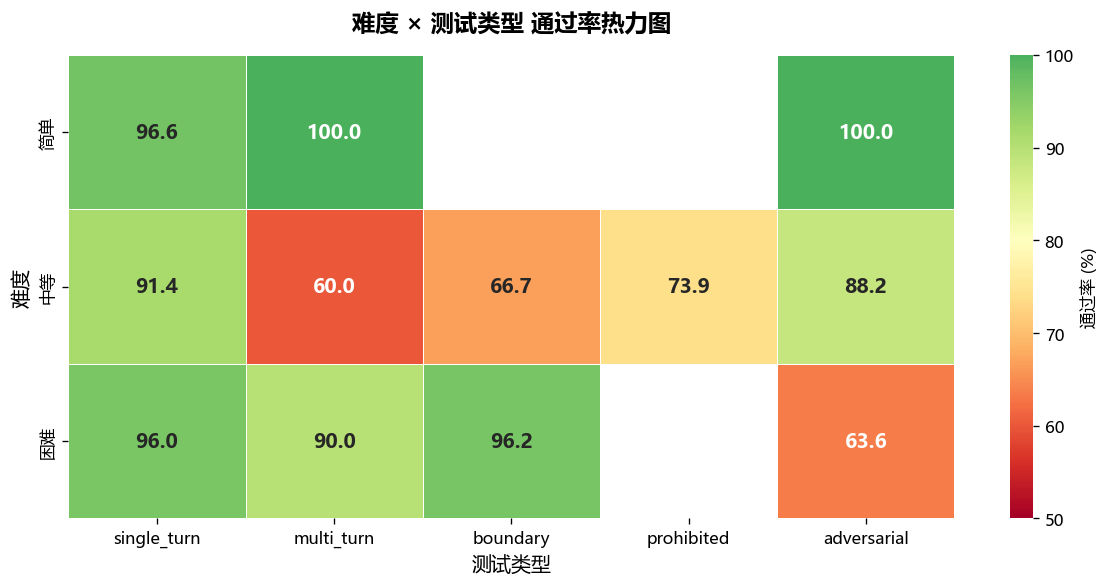

💾 已保存: charts/04_difficulty_type_heatmap.png

--- 热力图解读 ---
  最低通过率: 60.0% (中等 × multi_turn)
  最高通过率: 100.0% (简单 × multi_turn)


In [14]:
# ========== 图4：难度 × 测试类型 通过率热力图 ==========
pivot = df.pivot_table(
    values='route_passed',
    index='difficulty',
    columns='test_type',
    aggfunc='mean'
)

pivot = pivot.reindex(index=['简单', '中等', '困难'])
pivot = pivot[['single_turn', 'multi_turn', 'boundary', 'prohibited', 'adversarial']]

pivot_pct = pivot * 100

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(pivot_pct, annot=True, fmt='.1f', cmap='RdYlGn',
            vmin=50, vmax=100, center=80,
            cbar_kws={'label': '通过率 (%)'},
            linewidths=0.5, ax=ax,
            annot_kws={'fontsize': 12, 'fontweight': 'bold'})

ax.set_title('难度 × 测试类型 通过率热力图', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('测试类型', fontsize=12)
ax.set_ylabel('难度', fontsize=12)

plt.tight_layout()
plt.savefig('charts/04_difficulty_type_heatmap.png')
plt.show()

print('💾 已保存: charts/04_difficulty_type_heatmap.png')
print(f'\n--- 热力图解读 ---')
min_val = pivot_pct.min().min()
min_pos = pivot_pct.stack().idxmin()
max_val = pivot_pct.max().max()
max_pos = pivot_pct.stack().idxmax()
print(f'  最低通过率: {min_val:.1f}% ({min_pos[0]} × {min_pos[1]})')
print(f'  最高通过率: {max_val:.1f}% ({max_pos[0]} × {max_pos[1]})')

## 1.11 可视化：评分分布箱线图

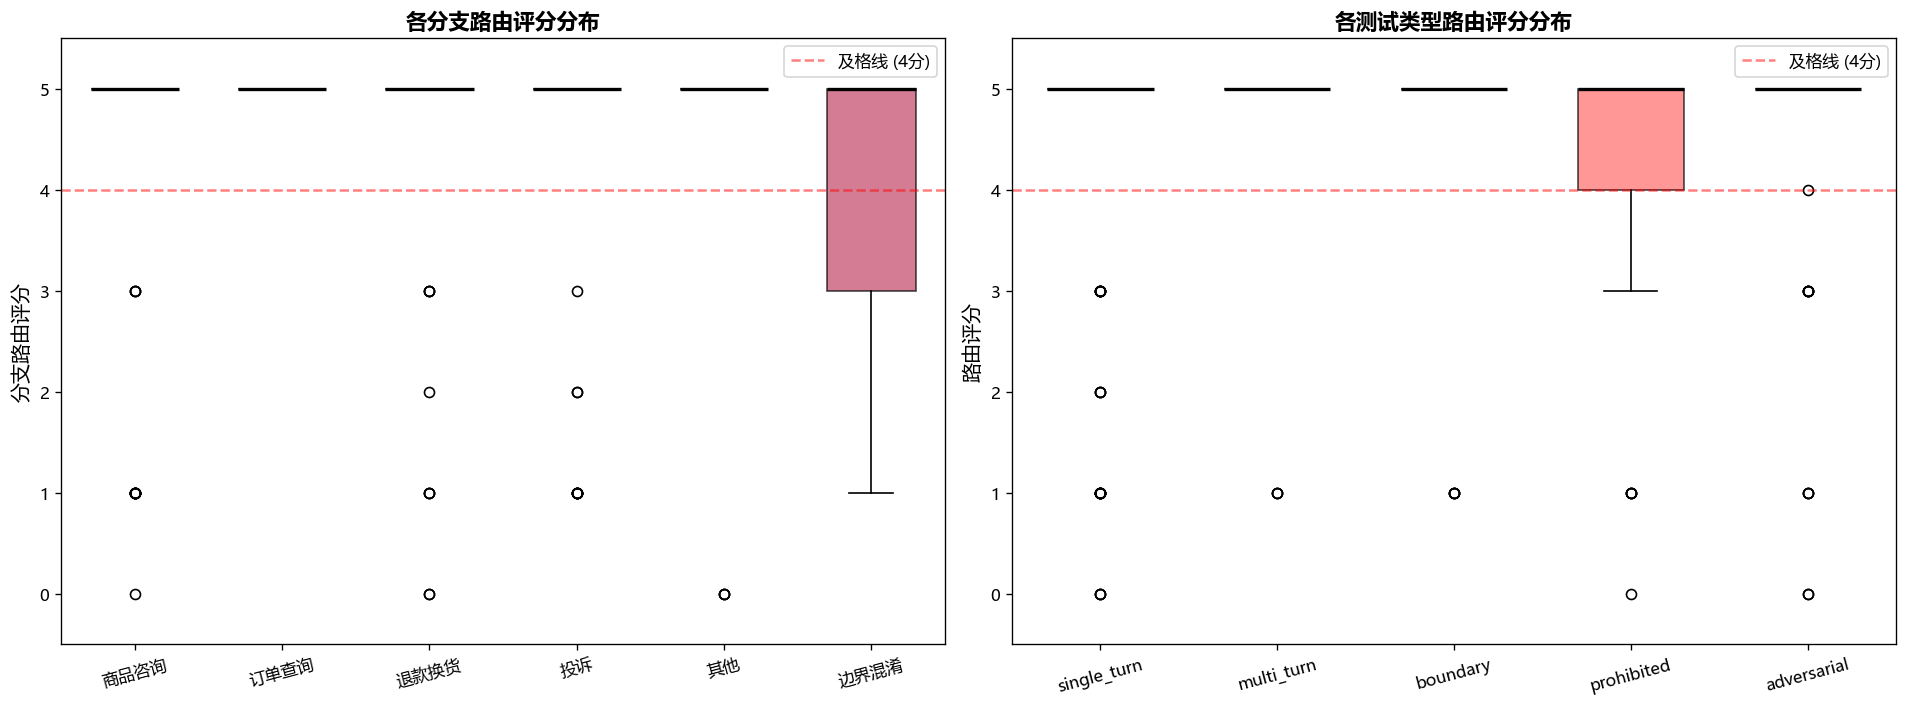

💾 已保存: charts/05_score_boxplot.png


In [15]:
# ========== 图5：各分支 branch_routing 评分箱线图 ==========
# 适配两种列名格式（Cell 5 展平版 vs Cell 30 json_normalize 版）
br_col = 'branch_routing' if 'branch_routing' in df.columns else 'score.branch_routing'
cat_col = 'category' if 'category' in df.columns else 'expected_branch'
tt_col = 'test_type' if 'test_type' in df.columns else 'test_type'

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 左图：按分支
branch_order = ['商品咨询', '订单查询', '退款换货', '投诉', '其他', '边界混淆']
box_data = [df[df[cat_col] == b][br_col].values for b in branch_order if len(df[df[cat_col] == b]) > 0]
box_labels = [b for b in branch_order if len(df[df[cat_col] == b]) > 0]
box_colors = [BRANCH_COLORS.get(b, '#888888') for b in box_labels]

bp = axes[0].boxplot(box_data, tick_labels=box_labels, patch_artist=True, widths=0.6,
                      medianprops={'color': 'black', 'linewidth': 2})
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[0].axhline(y=4, color='red', linestyle='--', alpha=0.5, label='及格线 (4分)')
axes[0].set_ylabel('分支路由评分', fontsize=12)
axes[0].set_title('各分支路由评分分布', fontsize=13, fontweight='bold')
axes[0].set_ylim(-0.5, 5.5)
axes[0].legend()
axes[0].tick_params(axis='x', rotation=15)

# 右图：按测试类型
type_order = ['single_turn', 'multi_turn', 'boundary', 'prohibited', 'adversarial']
type_box_data = [df[df[tt_col] == t][br_col].values for t in type_order if len(df[df[tt_col] == t]) > 0]
type_box_labels = [t for t in type_order if len(df[df[tt_col] == t]) > 0]
type_box_colors = [TYPE_COLORS.get(t, '#888888') for t in type_box_labels]

bp2 = axes[1].boxplot(type_box_data, tick_labels=type_box_labels, patch_artist=True, widths=0.6,
                       medianprops={'color': 'black', 'linewidth': 2})
for patch, color in zip(bp2['boxes'], type_box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[1].axhline(y=4, color='red', linestyle='--', alpha=0.5, label='及格线 (4分)')
axes[1].set_ylabel('路由评分', fontsize=12)
axes[1].set_title('各测试类型路由评分分布', fontsize=13, fontweight='bold')
axes[1].set_ylim(-0.5, 5.5)
axes[1].legend()
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('charts/05_score_boxplot.png')
plt.show()
print('💾 已保存: charts/05_score_boxplot.png')

## 1.12 可视化：综合仪表盘

C:\Users\Darren\AppData\Local\Temp\ipykernel_7028\3997136874.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


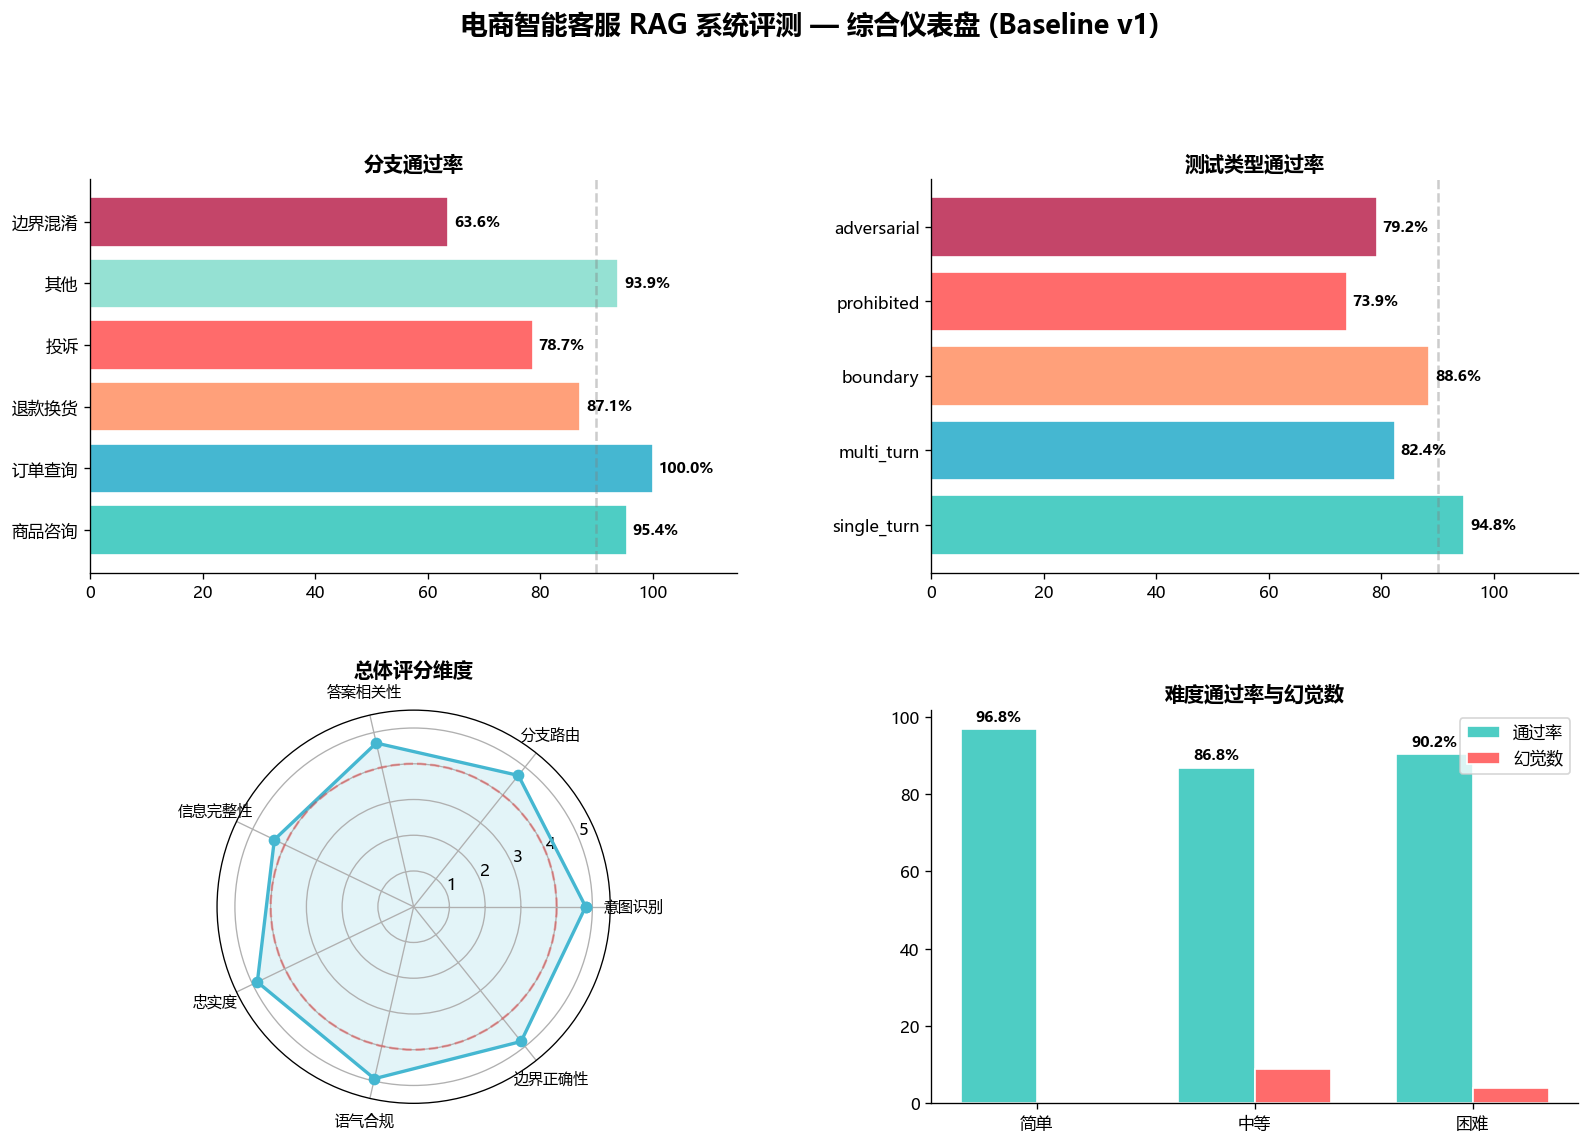

💾 已保存: charts/06_dashboard.png


In [16]:
# ========== 图6：综合仪表盘（4 合 1） ==========
fig = plt.figure(figsize=(16, 10))

gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3)

# --- 左上：分支通过率柱状图 ---
ax1 = fig.add_subplot(gs[0, 0])
bars = ax1.barh(branch_df['branch'], branch_df['pass_rate'] * 100,
                 color=[BRANCH_COLORS.get(b, '#888') for b in branch_df['branch']],
                 edgecolor='white', linewidth=1)
for bar, rate in zip(bars, branch_df['pass_rate']):
    ax1.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f'{rate*100:.1f}%', ha='left', va='center', fontsize=9, fontweight='bold')
ax1.axvline(x=90, color='gray', linestyle='--', alpha=0.4)
ax1.set_xlim(0, 115)
ax1.set_title('分支通过率', fontsize=12, fontweight='bold')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 右上：测试类型通过率 ---
ax2 = fig.add_subplot(gs[0, 1])
bars2 = ax2.barh(type_df['test_type'], type_df['pass_rate'] * 100,
                  color=[TYPE_COLORS.get(t, '#888') for t in type_df['test_type']],
                  edgecolor='white', linewidth=1)
for bar, rate in zip(bars2, type_df['pass_rate']):
    ax2.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f'{rate*100:.1f}%', ha='left', va='center', fontsize=9, fontweight='bold')
ax2.axvline(x=90, color='gray', linestyle='--', alpha=0.4)
ax2.set_xlim(0, 115)
ax2.set_title('测试类型通过率', fontsize=12, fontweight='bold')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# --- 左下：维度评分雷达图 ---
ax3 = fig.add_subplot(gs[1, 0], polar=True)
angles_short = [n / float(N) * 2 * np.pi for n in range(N)]
angles_short += angles_short[:1]
overall_values = [df[col].mean() for col in score_cols]
overall_values += overall_values[:1]
ax3.plot(angles_short, overall_values, 'o-', linewidth=2, color='#45B7D1', markersize=6)
ax3.fill(angles_short, overall_values, alpha=0.15, color='#45B7D1')
ax3.set_xticks(angles_short[:-1])
ax3.set_xticklabels(categories_radar, fontsize=9)
ax3.set_ylim(0, 5.5)
ax3.set_yticks([1, 2, 3, 4, 5])
ax3.set_title('总体评分维度', fontsize=12, fontweight='bold', pad=20)
ax3.axhline(y=4, color='red', linestyle='--', alpha=0.3)

# --- 右下：难度通过率 + 幻觉/违规统计 ---
ax4 = fig.add_subplot(gs[1, 1])
x = np.arange(len(diff_df))
width = 0.35
bars_pass = ax4.bar(x - width/2, diff_df['pass_rate'] * 100, width,
                     label='通过率', color='#4ECDC4', edgecolor='white')
bars_hal = ax4.bar(x + width/2, diff_df['hallucination'], width,
                    label='幻觉数', color='#FF6B6B', edgecolor='white')
ax4.set_xticks(x)
ax4.set_xticklabels(diff_df['difficulty'])
ax4.set_title('难度通过率与幻觉数', fontsize=12, fontweight='bold')
ax4.legend()
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
for bar, val in zip(bars_pass, diff_df['pass_rate']):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val*100:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

fig.suptitle('电商智能客服 RAG 系统评测 — 综合仪表盘 (Baseline v1)',
             fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('charts/06_dashboard.png')
plt.show()
print('💾 已保存: charts/06_dashboard.png')

## 1.13 关键发现总结

In [17]:
# ========== 模块一：描述性统计分析 — 关键发现（修正版 · 自包含） ==========
import json, pandas as pd, numpy as np

# ---------- 1. 加载数据 ----------
with open('eval_output/eval_results_20260807_142126.json', 'r', encoding='utf-8') as f:
    raw = json.load(f)
df = pd.json_normalize(raw) if isinstance(raw, list) else pd.DataFrame(raw)

total = len(df)
print(f"✅ 总样本数: {total}")

# ---------- 2. 字段常量（已按你的真实列名校准） ----------
S_INTENT    = 'score.intent_accuracy'       # 意图分数 0-5
S_BRANCH    = 'score.branch_routing'       # 路由分数 0-5
S_RELEVANCE = 'score.answer_relevance'
S_COMPLETE  = 'score.information_completeness'
S_FAITH     = 'score.faithfulness'
S_TONE      = 'score.tone_compliance'
S_BOUNDARY  = 'score.boundary_correctness'
S_HALLU     = 'score.is_hallucination'
S_VIOLATE   = 'score.must_not_violation'
S_CONTAINS  = 'score.contains_expected_points'
S_HANDOFF   = 'score.handoff_correctness'
S_TONE_COMP = 'score.tone_completeness'

GOLD_BRANCH = 'expected_branch'
GOLD_INTENT = 'expected_intent'

# ---------- 3. 样本级二值指标（✅ 不会超100%） ----------
# 通过 = 该维度拿满分 5 分
intent_ok   = (df[S_INTENT] == 5).sum()
branch_ok   = (df[S_BRANCH] == 5).sum()
hallu_cnt   = int(df[S_HALLU].astype(bool).sum()) if S_HALLU in df.columns else 0
violate_cnt = int(df[S_VIOLATE].astype(bool).sum()) if S_VIOLATE in df.columns else 0

# 整体通过率：所有评分维度都 >=5 才算完全通过（严口径）
# 也给出一个"宽松口径"做对比
dim_cols = [S_INTENT, S_BRANCH, S_RELEVANCE, S_COMPLETE, S_FAITH, S_TONE, S_BOUNDARY]
strict_pass = (df[dim_cols].ge(5).all(axis=1)).sum()
loose_pass  = (df[S_INTENT] >= 4).sum()  # 意图分>=4 即算可接受

# ---------- 4. 分支统计（用 expected_branch 分组） ----------
branch_rows = []
for b, grp in df.groupby(GOLD_BRANCH):
    n = len(grp)
    # 通过 = 路由满分 且 意图满分
    passed = ((grp[S_BRANCH] == 5) & (grp[S_INTENT] == 5)).sum()
    branch_rows.append({
        'branch': b, 'total': n, 'failed': n - passed,
        'pass_rate': passed / n * 100 if n else 0,
        'avg_branch_score': grp[S_BRANCH].mean(),
    })
branch_df = pd.DataFrame(branch_rows).sort_values('pass_rate').reset_index(drop=True)

# ---------- 5. 测试类型 / 难度统计 ----------
def group_rate(col):
    rows = []
    for v, grp in df.groupby(col):
        n = len(grp)
        passed = ((grp[S_BRANCH] == 5) & (grp[S_INTENT] == 5)).sum()
        rows.append({'value': v, 'total': n, 'pass_rate': passed/n*100 if n else 0})
    return pd.DataFrame(rows)

type_df = group_rate('test_type') if 'test_type' in df.columns else pd.DataFrame()
diff_df = group_rate('difficulty') if 'difficulty' in df.columns else pd.DataFrame()

# ---------- 6. 评分维度统计 ----------
score_cols_map = {
    '意图准确率': S_INTENT,
    '分支路由':   S_BRANCH,
    '答案相关性': S_RELEVANCE,
    '信息完整性': S_COMPLETE,
    '忠实度':     S_FAITH,
    '语气合规':   S_TONE,
    '边界正确':   S_BOUNDARY,
}
dim_stats = pd.DataFrame([
    {'dimension': k, 'mean': df[v].mean(), 'std': df[v].std()}
    for k, v in score_cols_map.items() if v in df.columns
]).sort_values('mean')
weakest     = dim_stats.iloc[0] if len(dim_stats) else {'dimension':'N/A','mean':0}
highest_var = dim_stats.sort_values('std', ascending=False).iloc[0] if len(dim_stats) else {'dimension':'N/A','std':0}

# ---------- 7. 难度反直觉校验 ----------
def safe_get(df_, key, default=0):
    try: return df_.loc[df_['value']==key, 'pass_rate'].values[0]
    except: return default
def safe_n(df_, key):
    try: return int(df_.loc[df_['value']==key, 'total'].values[0])
    except: return 0

mid_rate, mid_n = (safe_get(diff_df,'中等'), safe_n(diff_df,'中等'))
hard_rate, hard_n = (safe_get(diff_df,'困难'), safe_n(diff_df,'困难'))
diff_warning = " ⚠️ 样本量过小(n<20)，结论不可靠" if min(mid_n, hard_n) < 20 else ""

# ---------- 8. 打印关键发现 ----------
def fmt(x): return f"{x:.1f}%" if x is not None else "N/A"

print('=' * 64)
print('📋 模块一：描述性统计分析 — 关键发现（修正版）')
print('=' * 64)
print(f"""
【口径说明】
  · 路由/意图准确率 = (该维度==5的样本数) / 总样本数  ← 样本级二值
  · 通过率(严) = 全部维度均>=5 的样本占比
  · 通过率(松) = 意图分>=4 的样本占比
  · 幻觉/违规 = 受影响样本数 / 总样本数

1. 整体表现（n={total}）
   - 意图准确率:     {intent_ok/total*100:.1f}%  ({intent_ok}/{total})
   - 分支路由准确率: {branch_ok/total*100:.1f}%  ({branch_ok}/{total})
   - 幻觉样本占比:   {hallu_cnt/total*100:.1f}%  ({hallu_cnt} 条)
   - 违规样本占比:   {violate_cnt/total*100:.1f}%  ({violate_cnt} 条)
   - 整体通过率(严): {strict_pass/total*100:.1f}%  ({strict_pass}/{total})
   - 整体通过率(松): {loose_pass/total*100:.1f}%  ({loose_pass}/{total})

2. 分支表现（{len(branch_df)} 个分支，按通过率升序）
""")
for _, r in branch_df.iterrows():
    print(f"   · {r['branch']:12s}  通过率 {r['pass_rate']:5.1f}%  "
          f"(失败 {int(r['failed'])} 条, 平均路由分 {r['avg_branch_score']:.2f})")

if len(branch_df) >= 2:
    b_weak = branch_df.iloc[0]
    b_strong = branch_df.iloc[-1]
    print(f"""
   最强分支: {b_strong['branch']} ({b_strong['pass_rate']:.1f}%)
   原因参考: 该分支样本路由+意图均稳定满分
   最弱分支: {b_weak['branch']} ({b_weak['pass_rate']:.1f}%)
   失败数:   {int(b_weak['failed'])} 条
   可能原因: 分类器对该分支的边界 case 决策树未硬化
""")

if len(type_df):
    t_weak = type_df.sort_values('pass_rate').iloc[0]
    print(f"""3. 测试类型表现（{len(type_df)} 类）
   最弱: {t_weak['value']} ({t_weak['pass_rate']:.1f}%, n={int(t_weak['total'])})
   可能原因: 该类型 LLM 节点未内置专用约束清单
""")

print(f"""4. 评分维度
   最弱维度: {weakest['dimension']} (均值 {weakest['mean']:.2f})
   波动最大: {highest_var['dimension']} (标准差 {highest_var['std']:.2f})
   → 波动大 = 该维度输出不稳定，是优化优先候选

5. 难度反直觉校验{diff_warning}
   简单: {safe_get(diff_df,'简单'):.1f}%  中等: {mid_rate:.1f}%  困难: {hard_rate:.1f}%
   样本量: 简单={safe_n(diff_df,'简单')}, 中等={mid_n}, 困难={hard_n}
""")

failed_count = total - strict_pass
print(f"""6. 数据质量备注
   - 路由/意图用"满分5分"作为二值阈值，口径明确
   - 幻觉/违规为样本占比口径（非 token 级）
   - 难度结论{'已标红警告' if diff_warning else '样本量充足'}

→ 下一步: 进入模块二（失败归因分析），对 {failed_count} 条
  失败用例（严口径）进行根因标注（检索端 vs 生成端）
""")

✅ 总样本数: 505
📋 模块一：描述性统计分析 — 关键发现（修正版）

【口径说明】
  · 路由/意图准确率 = (该维度==5的样本数) / 总样本数  ← 样本级二值
  · 通过率(严) = 全部维度均>=5 的样本占比
  · 通过率(松) = 意图分>=4 的样本占比
  · 幻觉/违规 = 受影响样本数 / 总样本数

1. 整体表现（n=505）
   - 意图准确率:     93.7%  (473/505)
   - 分支路由准确率: 91.3%  (461/505)
   - 幻觉样本占比:   2.6%  (13 条)
   - 违规样本占比:   0.8%  (4 条)
   - 整体通过率(严): 64.0%  (323/505)
   - 整体通过率(松): 93.7%  (473/505)

2. 分支表现（5 个分支，按通过率升序）

   · 投诉            通过率  73.6%  (失败 14 条, 平均路由分 4.17)
   · 退款换货          通过率  85.0%  (失败 12 条, 平均路由分 4.53)
   · 其他            通过率  94.0%  (失败 3 条, 平均路由分 4.70)
   · 商品咨询          通过率  95.0%  (失败 14 条, 平均路由分 4.82)
   · 订单查询          通过率  97.5%  (失败 1 条, 平均路由分 4.90)

   最强分支: 订单查询 (97.5%)
   原因参考: 该分支样本路由+意图均稳定满分
   最弱分支: 投诉 (73.6%)
   失败数:   14 条
   可能原因: 分类器对该分支的边界 case 决策树未硬化

3. 测试类型表现（5 类）
   最弱: prohibited (73.9%, n=23)
   可能原因: 该类型 LLM 节点未内置专用约束清单

4. 评分维度
   最弱维度: 信息完整性 (均值 4.32)
   波动最大: 信息完整性 (标准差 1.28)
   → 波动大 = 该维度输出不稳定，是优化优先候选

5. 难度反直觉校验
   简单: 96.8%  中等: 86.8%  困难: 89.5%
   样本量: 简单=190, 中

In [19]:

# ========== 导出分析中间结果（供后续模块使用）==========
import json, pandas as pd

# 重新加载数据（自包含，不依赖 Cell 5 的 df 变量）
with open('eval_output/eval_results_20260807_142126.json', 'r', encoding='utf-8') as f:
    raw_results = json.load(f)

rows = []
for r in raw_results:
    s = r.get('score', {})
    def fmt_list(v):
        if isinstance(v, list):
            return ','.join(v)
        return str(v) if v else ''
    row = {
        'case_id': r.get('case_id', ''),
        'test_type': r.get('test_type', ''),
        'category': r.get('category', ''),
        'difficulty': r.get('difficulty', ''),
        'is_multi_turn': r.get('is_multi_turn', False),
        'user_query': r.get('user_query', ''),
        'expected_intent': r.get('expected_intent', ''),
        'expected_branch': r.get('expected_branch', ''),
        'expected_if_else_path': fmt_list(r.get('expected_if_else_path', '')),
        'expected_answer_contains': fmt_list(r.get('expected_answer_contains', '')),
        'must_not': fmt_list(r.get('must_not', '')),
        'expected_complaint_level': r.get('expected_complaint_level'),
        'expected_human_handoff': r.get('expected_human_handoff', False),
        'expected_retrieval_hit': r.get('expected_retrieval_hit'),
        'conversation_id': r.get('conversation_id', ''),
        'boundary_value': r.get('boundary_value'),
        'intent_accuracy': s.get('intent_accuracy', 0),
        'branch_routing': s.get('branch_routing', 0),
        'answer_relevance': s.get('answer_relevance', 0),
        'information_completeness': s.get('information_completeness', 0),
        'faithfulness': s.get('faithfulness', 0),
        'tone_compliance': s.get('tone_compliance', 0),
        'boundary_correctness': s.get('boundary_correctness', 0),
        'must_not_violation': s.get('must_not_violation', False),
        'is_hallucination': s.get('is_hallucination', False),
        'contains_expected_points': s.get('contains_expected_points', False),
        'handoff_correctness': s.get('handoff_correctness', -1),
        'comment': s.get('comment', ''),
        'actual_response': r.get('actual_response', ''),
    }
    rows.append(row)

df = pd.DataFrame(rows)
df['route_passed'] = df['branch_routing'] >= 4
df['route_passed_strict'] = df['branch_routing'] == 5

import os
os.makedirs('analysis_output', exist_ok=True)

# 导出完整数据
df.to_csv('analysis_output/module1_cleaned_data.csv', index=False, encoding='utf-8-sig')

# 导出失败用例（宽松口径）
failed_loose = df[~df['route_passed']]
failed_loose.to_csv('analysis_output/module1_failed_cases.csv', index=False, encoding='utf-8-sig')

# 导出失败用例（严格口径）
failed_strict = df[~df['route_passed_strict']]
failed_strict.to_csv('analysis_output/module1_failed_cases_strict.csv', index=False, encoding='utf-8-sig')

print('✅ 模块一导出完成')
print(f'   - module1_cleaned_data.csv (完整数据, {len(df)} 条)')
print(f'   - module1_failed_cases.csv (宽松口径失败, {len(failed_loose)} 条 -> 模块二输入)')
print(f'   - module1_failed_cases_strict.csv (严格口径失败, {len(failed_strict)} 条)')


✅ 模块一导出完成
   - module1_cleaned_data.csv (完整数据, 505 条)
   - module1_failed_cases.csv (宽松口径失败, 43 条 -> 模块二输入)
   - module1_failed_cases_strict.csv (严格口径失败, 44 条)
